# Airline Delay Analysis

**Question:** Which causes, carriers, airports and months account for the most arrival delay minutes across the US airline network between January 2024 and June 2025?

MSc Business Analytics coursework, University of Greenwich (2025–26). Module: Business Data Mining and Visual Analytics (COMP1943).

## Data Understanding
This study looks at the main factors that cause airline arrival delays. The dataset includes 34,016 records and 21 variables showing monthly flight activity for major U.S. carriers and airports between 2024 and 2025. Each record represents a carrier–airport pair for one month, giving an overall view of airline performance across the national network.

The analysis focuses on variables that explain total arrival delay minutes. These include arr_delay (the dependent variable) and several related factors such as carrier_delay, weather_delay, nas_delay, security_delay, and late_aircraft_delay. Each of these shows a different cause of delay linked to airline operations, weather, traffic systems, security checks, or late incoming flights. Other variables like arr_flights (total arrivals) and arr_del15 (flights delayed more than 15 minutes) help measure the number and frequency of delays. Categorical variables such as carrier_name, airport_name, year, and month allow for comparisons across airlines, airports, and time periods.

Overall, the dataset gives a clear picture of how different airlines and airports perform under varying conditions. By combining delay causes, operational volumes, and time-based data, it helps reveal where inefficiencies occur and which factors have the greatest influence on arrival delays. This understanding supports deeper analysis of performance trends and potential improvement areas in airline operations.

## Loading Libraries
The following Python libraries are imported to manage, analyse, and visualise the dataset effectively.

In [1]:
# Importing essential libraries
import pandas as pd                                       # For reading, cleaning and managing tabular data
import numpy as np                                        # For performing numerical operations and working with arrays
import matplotlib.pyplot as plt                           # For creating visualisations and charts
import seaborn as sns                                     # For advanced, visually appealing statistical plots


## Loading the Dataset

In [2]:
df = pd.read_excel("../data/Airline_Delay.xlsx")

## Data Pre-processing
A systematic pre-processing procedure will be applied to ensure the dataset's consistency, completeness, and readiness for analysis. The process will begin with standard exploratory checks for missing values, duplicate records, and data types. Columns containing no useful information will be removed to maintain dataset efficiency and reduce noise, while summary checks will confirm the validity of numerical ranges and categorical labels.

For numerical variables, missing values will be replaced with their respective median values. This approach will reduce the influence of outliers and maintain the central tendency of the data without distorting its distribution. For categorical variables, missing entries such as carrier, airport, or airport_name will be replaced with the placeholder "Unknown" to prevent data loss and preserve category representation during visualisation. Binary or indicator variables containing missing values will be assigned a value of 0, as these fields typically represent event occurrences or flag indicators. Additional consistency checks will also be performed to ensure there are no negative values in delay fields.

Duplicate rows will be identified and removed to prevent double counting and maintain the accuracy of totals and averages. Potential outliers will be inspected visually but retained if they represent genuine operational differences rather than data entry errors. Data types will be verified to ensure numeric fields are stored as numeric and categorical attributes as strings, allowing proper statistical operations. Column names have already been reviewed for clarity and consistency. Since all variables followed a standardised and descriptive naming convention, no renaming will be necessary.

All cleaning steps will follow standard, well-documented data-handling practices to ensure transparency and reproducibility while avoiding unnecessary complexity. After cleaning, validation checks will confirm that no missing values remain in the key analytical variables. Overall, this pre-processing procedure will generate a dataset that is statistically coherent, free from duplication, and analytically consistent. The cleaned and validated data will provide a reliable foundation for descriptive statistics, correlation analysis, and visualisations aimed at identifying operational delay patterns across carriers and airports.

In [3]:
# Inspecting the dataset to understand its structure and contents

# Viewing the number of rows and columns
print("Shape of dataset:", df.shape)

# Checking the first few rows to see how the data looks
display(df.head())

# Checking basic information about each column
display(df.info())

# Getting summary statistics for all columns
display(df.describe(include='all'))

Shape of dataset: (34016, 21)


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2025,6,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",90.0,26.0,8.63,3.24,...,0.0,9.72,4.0,0.0,1884.0,561.0,223.0,282.0,0.0,818.0
1,2025,6,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",5.0,1.0,0.00,0.00,...,0.0,1.00,0.0,0.0,124.0,0.0,0.0,0.0,0.0,124.0
2,2025,6,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",69.0,23.0,7.21,1.82,...,0.0,5.32,2.0,0.0,1698.0,981.0,54.0,294.0,0.0,369.0
3,2025,6,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",155.0,43.0,12.78,2.69,...,0.0,17.19,9.0,0.0,2877.0,827.0,198.0,517.0,0.0,1335.0
4,2025,6,9E,Endeavor Air Inc.,ALB,"Albany, NY: Albany International",86.0,29.0,9.32,0.00,...,0.0,15.61,4.0,0.0,1934.0,638.0,0.0,194.0,0.0,1102.0


<class 'pandas.DataFrame'>
RangeIndex: 34016 entries, 0 to 34015
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 34016 non-null  int64  
 1   month                34016 non-null  int64  
 2   carrier              34016 non-null  str    
 3   carrier_name         34016 non-null  str    
 4   airport              34016 non-null  str    
 5   airport_name         34016 non-null  str    
 6   arr_flights          33997 non-null  float64
 7   arr_del15            33989 non-null  float64
 8   carrier_ct           33997 non-null  float64
 9   weather_ct           33997 non-null  float64
 10  nas_ct               33997 non-null  float64
 11  security_ct          33997 non-null  float64
 12  late_aircraft_ct     33997 non-null  float64
 13  arr_cancelled        33997 non-null  float64
 14  arr_diverted         33997 non-null  float64
 15  arr_delay            33997 non-null  float64
 1

None

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,34016.000000,34016.000000,34016,34016,34016,34016,33997.000000,33989.000000,33997.000000,33997.000000,...,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000,33997.000000
unique,NaN,NaN,21,25,362,372,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,OO,SkyWest Airlines Inc.,PIT,"Pittsburgh, PA: Pittsburgh International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,4265,4265,319,319,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2024.335342,5.502999,NaN,NaN,NaN,NaN,334.096067,69.148931,21.507606,2.741031,...,0.159762,25.296088,4.782040,0.854017,5028.571492,1674.458423,323.867018,997.368238,7.673177,2025.156073
std,0.472117,3.307254,NaN,NaN,NaN,NaN,965.314039,200.990273,56.291232,10.117925,...,0.704344,82.376530,23.407825,3.877638,16709.788725,5673.996966,1306.370249,3866.246115,38.472569,7175.996229
min,2024.000000,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2024.000000,3.000000,NaN,NaN,NaN,NaN,44.000000,7.000000,2.240000,0.000000,...,0.000000,1.660000,0.000000,0.000000,401.000000,117.000000,0.000000,47.000000,0.000000,91.000000
50%,2024.000000,5.000000,NaN,NaN,NaN,NaN,90.000000,18.000000,6.250000,0.640000,...,0.000000,5.640000,1.000000,0.000000,1200.000000,387.000000,30.000000,173.000000,0.000000,400.000000
75%,2025.000000,8.000000,NaN,NaN,NaN,NaN,222.000000,48.000000,17.050000,2.020000,...,0.000000,16.870000,3.000000,1.000000,3324.000000,1182.000000,212.000000,522.000000,0.000000,1320.000000


In [4]:
# Checking the dataset for missing values and duplicates
# Counting missing values in each column
display(df.isnull().sum())

# Checking for duplicate rows
display(df.duplicated().sum())

year                    0
month                   0
carrier                 0
carrier_name            0
airport                 0
airport_name            0
arr_flights            19
arr_del15              27
carrier_ct             19
weather_ct             19
nas_ct                 19
security_ct            19
late_aircraft_ct       19
arr_cancelled          19
arr_diverted           19
arr_delay              19
carrier_delay          19
weather_delay          19
nas_delay              19
security_delay         19
late_aircraft_delay    19
dtype: int64

np.int64(3)

In [5]:
# Dropping completely empty columns
df = df.dropna(axis=1, how='all')

# Filling numeric missing values with median
df = df.fillna(df.median(numeric_only=True))

# Filling missing text values with 'Unknown'
# (pandas 3 stores text columns as 'str' rather than 'object', so both are checked)
for col in df.columns:
    if df[col].dtype == 'object' or pd.api.types.is_string_dtype(df[col]):
        df[col] = df[col].fillna('Unknown')

# Filling missing binary values (0/1) with 0
for col in df.columns:
    if df[col].dropna().isin([0, 1]).all():
        df[col] = df[col].fillna(0)

# Removing duplicates
df = df.drop_duplicates()

print("Data cleaning completed.")

Data cleaning completed.


In [6]:
# Confirming that all missing values and duplicates are handled

# Checking again for missing values
display(df.isnull().sum())

# Checking dataset shape after cleaning
print("New shape of dataset:", df.shape)

# Reviewing updated dataset info
display(df.info())

# Displaying updated statistics for validation
display(df.describe(include='all'))

year                   0
month                  0
carrier                0
carrier_name           0
airport                0
airport_name           0
arr_flights            0
arr_del15              0
carrier_ct             0
weather_ct             0
nas_ct                 0
security_ct            0
late_aircraft_ct       0
arr_cancelled          0
arr_diverted           0
arr_delay              0
carrier_delay          0
weather_delay          0
nas_delay              0
security_delay         0
late_aircraft_delay    0
dtype: int64

New shape of dataset: (34013, 21)
<class 'pandas.DataFrame'>
Index: 34013 entries, 0 to 34015
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   year                 34013 non-null  int64  
 1   month                34013 non-null  int64  
 2   carrier              34013 non-null  str    
 3   carrier_name         34013 non-null  str    
 4   airport              34013 non-null  str    
 5   airport_name         34013 non-null  str    
 6   arr_flights          34013 non-null  float64
 7   arr_del15            34013 non-null  float64
 8   carrier_ct           34013 non-null  float64
 9   weather_ct           34013 non-null  float64
 10  nas_ct               34013 non-null  float64
 11  security_ct          34013 non-null  float64
 12  late_aircraft_ct     34013 non-null  float64
 13  arr_cancelled        34013 non-null  float64
 14  arr_diverted         34013 non-null  float64
 15  arr_delay         

None

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
count,34013.000000,34013.000000,34013,34013,34013,34013,34013.000000,34013.000000,34013.000000,34013.000000,...,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000,34013.000000
unique,NaN,NaN,21,25,362,372,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,OO,SkyWest Airlines Inc.,PIT,"Pittsburgh, PA: Pittsburgh International",NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,4265,4265,319,319,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2024.335284,5.502955,NaN,NaN,NaN,NaN,333.932585,69.100373,21.497436,2.739703,...,0.159687,25.279581,4.778643,0.853615,5025.529445,1673.447270,323.674742,996.809485,7.669568,2023.762532
std,0.472096,3.307397,NaN,NaN,NaN,NaN,965.069917,200.915000,56.277351,10.115491,...,0.704186,82.349757,23.401330,3.876770,16704.916692,5672.353011,1306.050458,3865.333659,38.463879,7173.648003
min,2024.000000,1.000000,NaN,NaN,NaN,NaN,1.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2024.000000,3.000000,NaN,NaN,NaN,NaN,44.000000,7.000000,2.240000,0.000000,...,0.000000,1.660000,0.000000,0.000000,401.000000,117.000000,0.000000,47.000000,0.000000,91.000000
50%,2024.000000,5.000000,NaN,NaN,NaN,NaN,90.000000,18.000000,6.250000,0.640000,...,0.000000,5.640000,1.000000,0.000000,1200.000000,387.000000,30.000000,173.000000,0.000000,400.000000
75%,2025.000000,8.000000,NaN,NaN,NaN,NaN,221.000000,48.000000,17.010000,2.010000,...,0.000000,16.860000,3.000000,1.000000,3323.000000,1181.000000,212.000000,521.000000,0.000000,1318.000000


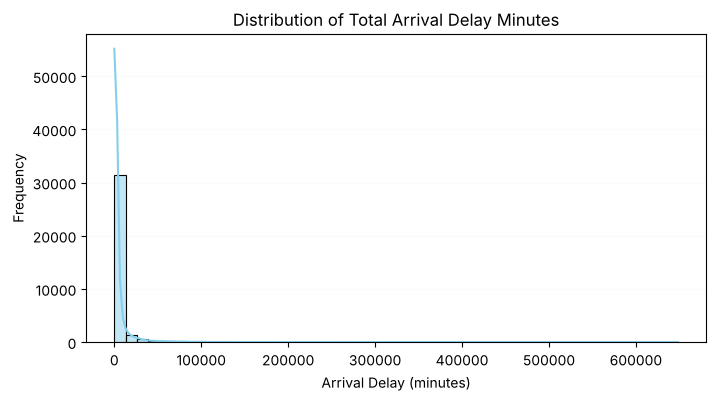

In [7]:
# Visualising the distribution of total arrival delay
plt.figure(figsize=(8,4))
sns.histplot(df['arr_delay'], bins=50, kde=True, color='skyblue', edgecolor='black')
plt.title('Distribution of Total Arrival Delay Minutes')
plt.xlabel('Arrival Delay (minutes)')
plt.ylabel('Frequency')
plt.grid(axis='y', alpha=.05)
plt.show()

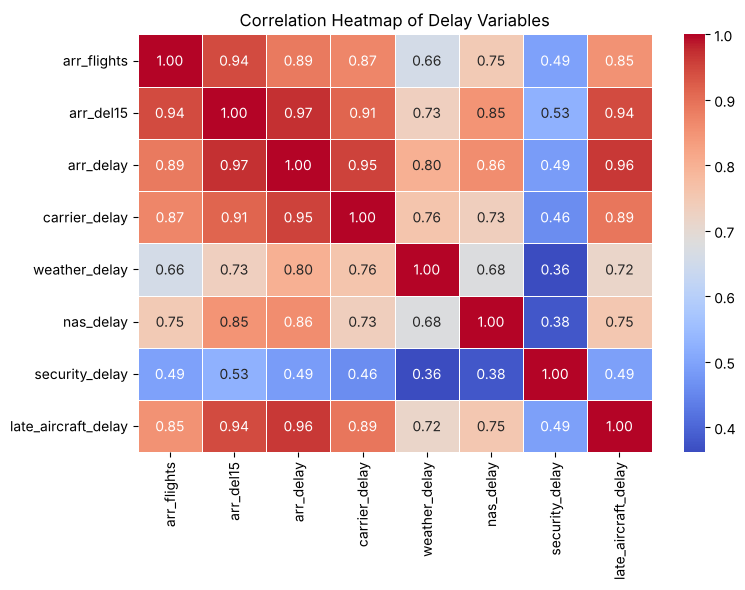

In [8]:
# Checking correlation between key numerical variables
corr_vars = ['arr_flights', 'arr_del15', 'arr_delay',
             'carrier_delay', 'weather_delay', 'nas_delay',
             'security_delay', 'late_aircraft_delay']

plt.figure(figsize=(8,6))
sns.heatmap(df[corr_vars].corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Heatmap of Delay Variables')
plt.tight_layout()
plt.savefig('../figures/correlation_heatmap.png', dpi=150, bbox_inches='tight')  # saving figure for the README
plt.show()

In [9]:
# Printing the exact figures quoted in the
# Data Description below, so they can be read directly from the output
print("Correlation with arr_delay:")
print(df[corr_vars].corr()['arr_delay'].drop('arr_delay').sort_values(ascending=False).round(3))

print("\nTop 5 carriers by total arrival delay minutes:")
print(df.groupby('carrier_name')['arr_delay'].sum().nlargest(5))

print("\nTop 5 airports by total arrival delay minutes:")
print(df.groupby('airport')['arr_delay'].sum().nlargest(5))

# Share of cause-attributed delay minutes
cause_cols = ['carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']
print("\nShare of cause-attributed delay minutes (%):")
print((df[cause_cols].sum() / df[cause_cols].sum().sum() * 100).round(1).sort_values(ascending=False))

Correlation with arr_delay:
arr_del15              0.971
late_aircraft_delay    0.964
carrier_delay          0.953
arr_flights            0.886
nas_delay              0.858
weather_delay          0.801
security_delay         0.486
Name: arr_delay, dtype: float64

Top 5 carriers by total arrival delay minutes:
carrier_name
American Airlines Network    31109720.0
Southwest Airlines           23583789.0
Delta Air Lines Network      19846672.0
SkyWest Airlines Inc.        18167919.0
United Air Lines Network     16432754.0
Name: arr_delay, dtype: float64

Top 5 airports by total arrival delay minutes:
airport
DFW    10144832.0
ORD     8482907.0
ATL     7340319.0
DEN     6954625.0
CLT     6663899.0
Name: arr_delay, dtype: float64

Share of cause-attributed delay minutes (%):
late_aircraft_delay    40.3
carrier_delay          33.3
nas_delay              19.8
weather_delay           6.4
security_delay          0.2
dtype: float64


## Data Description

### Overview
After cleaning and validation, the dataset contains **34,013 records** and **21 variables**, representing monthly operational data for major U.S. airlines and airports during **2024–2025**. It includes numerical variables such as arrival delay minutes, delayed flights, and cause-specific delay minutes, along with categorical variables including airline, airport, month, and year.

### Numeric Summaries
Descriptive statistics from the raw data, before cleaning, show that the average number of arriving flights per carrier airport month is **334**, while the **mean total arrival delay** is approximately **5,028 minutes**. The **median delay** is **1,200 minutes**, indicating a **strong right-skew** caused by a small number of heavily delayed carrier and airport combinations. The **standard deviation** of **16,709 minutes** reflects substantial variation across different airlines and airports.

Mean delay-cause minutes per carrier–airport month (before cleaning):

- **late_aircraft_delay:** 2,025 (σ = 7,176)
- **carrier_delay:** 1,674 (σ = 5,674)
- **nas_delay:** 997 (σ = 3,866)
- **weather_delay:** 324 (σ = 1,306)
- **security_delay:** 8 (σ = 38)

These values show that **late aircraft** and **carrier operations** contribute the most to overall delay totals.

### Distributions and Histogram
The histogram of **arr_delay** shows a strongly right-skewed distribution. Most carrier-airport months record relatively low arrival delay minutes, while a much smaller number contain extremely high delay minutes. These large delay spikes stretch the upper end of the distribution and significantly increase the overall mean and standard deviation seen in the summary statistics.

### Correlations Between Key Variables
The correlation heatmap reveals strong positive associations between **arr_delay** and:

- **arr_del15:** r = 0.971
- **late_aircraft_delay:** r = 0.964
- **carrier_delay:** r = 0.953
- **nas_delay:** r = 0.858
- **weather_delay:** r = 0.801

Security delays show a weaker correlation (**r = 0.486**). These patterns indicate that **late-arriving aircraft** and **airline-controlled processes** are the causes most closely associated with total arrival delay minutes. Because `arr_delay` is the sum of the five cause fields, these correlations are partly built in, so the share of delay minutes by cause (below) is the clearer evidence.

### Patterns Across Categories
Delay totals are heavily concentrated among the largest U.S. hub carriers and airports. Top contributors to total arrival delay include:

- **Carriers:** American Airlines Network, Southwest Airlines, Delta Air Lines Network, SkyWest Airlines, United Airlines
- **Airports:** Dallas/Fort Worth (DFW), Chicago O'Hare (ORD), Atlanta (ATL), Denver (DEN), Charlotte (CLT)

These observations show that **network size**, **traffic volume**, and **operational scale** strongly influence delay patterns across the national aviation system.

## Visualisation

### 1. Proportion of Total Delay Minutes by Cause

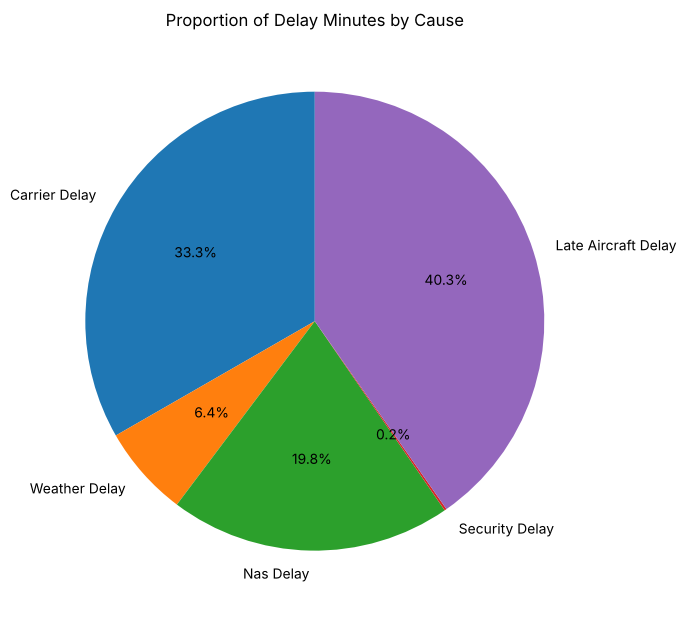

In [10]:
# Calculating total delay minutes for each delay cause
delay_totals = df[[
    'carrier_delay',
    'weather_delay',
    'nas_delay',
    'security_delay',
    'late_aircraft_delay'
]].sum()

# Plotting the proportions as a pie chart
plt.figure(figsize=(7,7))
plt.pie(
    delay_totals,
    labels=delay_totals.index.str.replace('_', ' ').str.title(),
    autopct='%1.1f%%',
    startangle=90
)
plt.title('Proportion of Delay Minutes by Cause')
plt.tight_layout()
plt.savefig('../figures/delay_minutes_by_cause.png', dpi=150, bbox_inches='tight')  # saving figure for the README
plt.show()

The chart shows that late aircraft and carrier related delays dominate overall disruption, together accounting for the majority of total delay minutes.

### 2. Showing Which Airlines Have the Highest Average Delay per Operated Flight

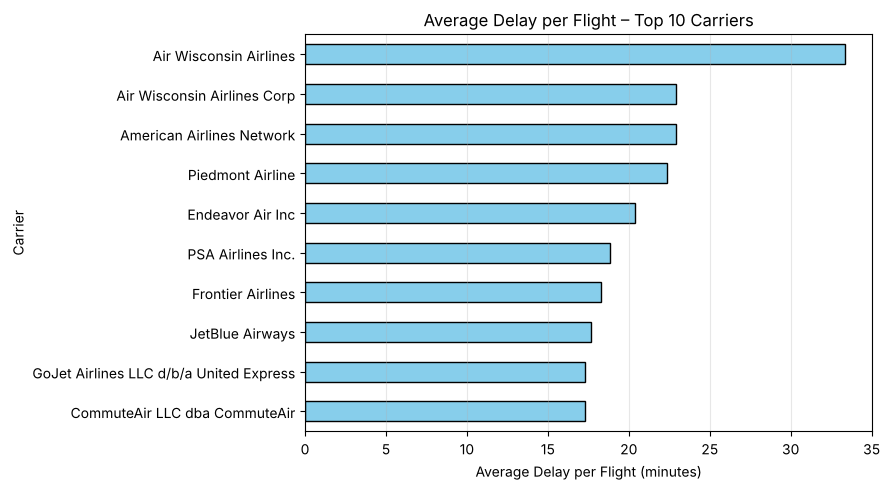

In [11]:
# Calculating delay per flight for each carrier
df['delay_per_flight'] = df['arr_delay'] / df['arr_flights']
top10_carriers = df.groupby('carrier_name')['delay_per_flight'].mean().sort_values(ascending=False).head(10)

# Plotting horizontal bar chart for top 10 carriers
plt.figure(figsize=(9,5))
top10_carriers.plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Average Delay per Flight – Top 10 Carriers')
plt.xlabel('Average Delay per Flight (minutes)')
plt.ylabel('Carrier')
plt.gca().invert_yaxis()   # Shows largest on top
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

The comparison shows Air Wisconsin Airlines with the highest average delay per operated flight, although that bar rests on only four records filed under a second version of the carrier's name.

### 3. Comparing Controllable vs Uncontrollable Delays for the Top 5 Airlines

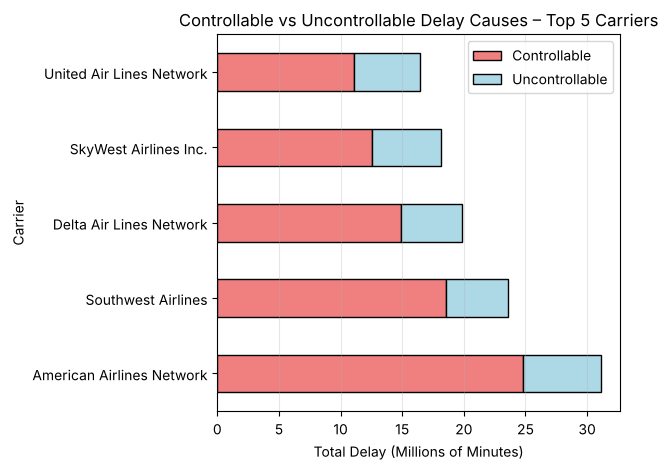

In [12]:
# Aggregating causes per carrier
cause_cols = ['carrier_delay','weather_delay','nas_delay','security_delay','late_aircraft_delay']
carrier_cause = df.groupby('carrier_name')[cause_cols].sum()

# Grouping controllable vs uncontrollable
carrier_cause['Controllable'] = carrier_cause['carrier_delay'] + carrier_cause['late_aircraft_delay']
carrier_cause['Uncontrollable'] = carrier_cause['weather_delay'] + carrier_cause['nas_delay'] + carrier_cause['security_delay']

# Calculating % controllable
carrier_cause['Pct_Controllable'] = (carrier_cause['Controllable'] / (carrier_cause['Controllable'] + carrier_cause['Uncontrollable'])) * 100

# Selecting top 5 total delay carriers
top5 = carrier_cause.sum(axis=1).sort_values(ascending=False).head(5).index

# Plotting
plt.figure(figsize=(8,5))
carrier_cause.loc[top5, ['Controllable','Uncontrollable']].div(1_000_000).plot(
    kind='barh', stacked=True, color=['lightcoral','lightblue'], edgecolor='black'
)
plt.title('Controllable vs Uncontrollable Delay Causes – Top 5 Carriers')
plt.xlabel('Total Delay (Millions of Minutes)')
plt.ylabel('Carrier')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/controllable_vs_uncontrollable_top5_carriers.png', dpi=150, bbox_inches='tight')  # saving figure for the README
plt.show()

The visual indicates that controllable delays account for a major share of total delays across all five carriers, with American Airlines Network contributing the highest volume.

### 4. Tracking How Total National Delays Change Over Months

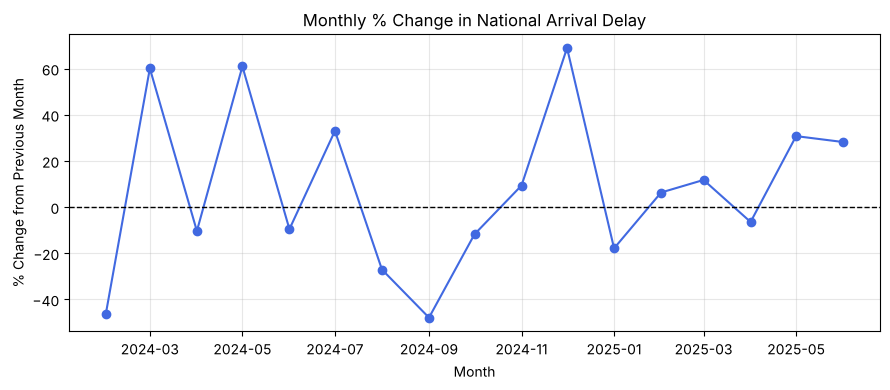

In [13]:
# Summing delay by month
monthly = df.groupby(['year','month'])['arr_delay'].sum().reset_index()
monthly['date'] = pd.to_datetime(monthly['year'].astype(str) + '-' + monthly['month'].astype(str) + '-01')
monthly = monthly.sort_values('date')
monthly['pct_change'] = monthly['arr_delay'].pct_change() * 100

# Line chart showing percentage change over time
plt.figure(figsize=(9,4))
plt.plot(monthly['date'], monthly['pct_change'], marker='o', color='royalblue')
plt.title('Monthly % Change in National Arrival Delay')
plt.xlabel('Month')
plt.ylabel('% Change from Previous Month')
plt.axhline(0, color='black', linestyle='--', linewidth=1)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../figures/monthly_pct_change_national_delay.png', dpi=150, bbox_inches='tight')  # saving figure for the README
plt.show()

National delay levels rise and fall sharply across the year, reflecting strong seasonal and operational variation.

### 5. Airports with the Most Stable Monthly Delay Levels

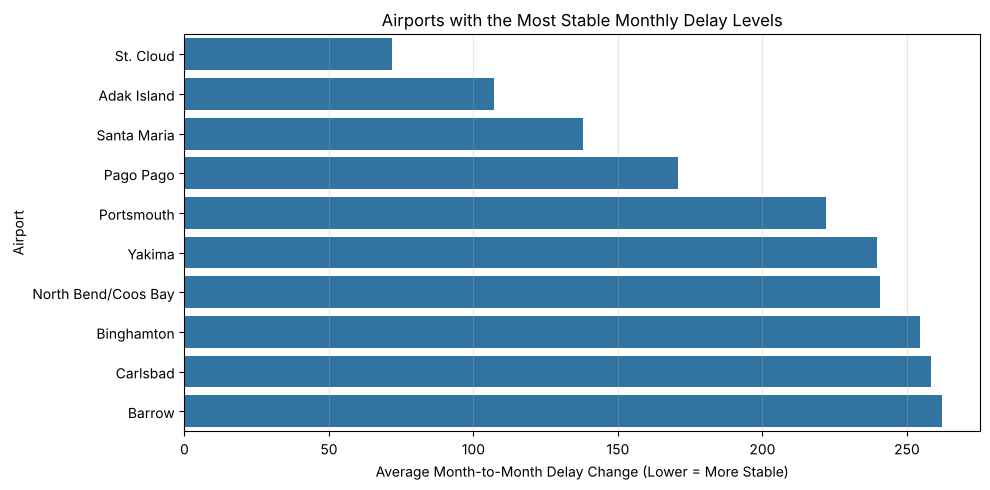

In [14]:
# Stability of Monthly Delay Levels

# Total monthly delay per airport
monthly = df.groupby(['airport_name', 'month'])['arr_delay'].sum().reset_index()

# Compute month to month change in delay
monthly = monthly.sort_values(['airport_name', 'month'])
monthly['delay_change'] = monthly.groupby('airport_name')['arr_delay'].diff().abs()

# Average change per airport (lower = more stable)
stability = monthly.groupby('airport_name')['delay_change'].mean().dropna()

# Top 10 most stable airports
top10_stable = stability.nsmallest(10)

# Bar chart
plt.figure(figsize=(10,5))
sns.barplot(
    x=top10_stable.values,
    y=[name.split(',')[0] for name in top10_stable.index]
)
plt.title('Airports with the Most Stable Monthly Delay Levels')
plt.xlabel('Average Month-to-Month Delay Change (Lower = More Stable)')
plt.ylabel('Airport')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

The chart shows that smaller regional airports such as St. Cloud and Adak Island experience the most consistent delay levels, while others show larger fluctuations.

## Conclusion
The analysis shows that airline delays vary widely across time, carriers, and airports. Monthly totals rise and fall sharply, although 18 months of data is too short to confirm a seasonal pattern, while the breakdown of delay types confirms that late-aircraft and carrier-related factors are the primary sources of disruption. Comparisons across airlines highlight clear differences in controllable delay performance and average delay per operated flight. The stability measure also shows that some airports maintain steady delay levels, whereas others fluctuate sharply from month to month. Overall, the results indicate that both operational practices and broader network pressures shape national delay patterns.

### Next Steps
- Use monthly delay trends to anticipate peak disruption periods and adjust staffing or schedules accordingly.
- Examine controllable delay causes to identify specific airline processes that consistently create operational bottlenecks.
- Investigate airports with high delay volatility to understand whether resource limitations or coordination issues are driving fluctuations.
- Focus on reducing late-aircraft delays by improving turnaround speed and preventing delays from affecting later flights.